# Open Library Public Domain Opportunity Radar

## 1 Executive Summary

This report screens the full Open Library catalogue, which held 41.7 million works and 56.9 million editions on 31 October 2026, for books that are or will become free to republish on **1 January 2027**. It compares two legal regimes, the publication-based terms of the **United States** and the author's life plus 50 years used in the **Philippines**, before measuring reader demand (13.2 million reading-log entries and 1.07 million ratings) and current supply (recent editions, publishers, scans and Filipino-language editions). Every step ran in PySpark, with the cleaned tables saved as Parquet.

**Main findings**

- **6.06 million works (14.5%) are potentially public domain** under at least one of the two rules. Of these, **1.51 million are free only under the Philippine rule**, confirming that life + 50 releases many 20th-century works decades before the US does, as seen in *Think and Grow Rich*, *How to Win Friends and Influence People*, *The Hobbit* and *Animal Farm*.
- **96,544 works enter the public domain on 1 January 2027**, made up of 71,520 first published in 1931 (US), 24,888 whose last author died in 1976 (Philippines) and 136 that qualify under both rules. The Philippine group is dominated by **Agatha Christie**, who died in 1976 and whose 1,012 catalogued works carry 22,008 Want-to-Read entries, or 52% of all demand among 2027 entrants, yet **none of them has a Filipino-language edition**.
- Readers want older works about as much as newer ones, since the mean rating sits close to 4.0 stars in every rights group. Want-to-Read entries fell over the most recent 12 months in every group, but public-domain works declined least (−5.7% against −31.7% for post-1978 works), lifting their share of demand from 5.1% to 6.7%.
- Supply is thin and almost entirely non-Filipino: only 1.8% of US public-domain works have an edition from 2017 onwards, while just 4,252 of the 41.7 million works (0.01%) have any edition in Tagalog or Filipino.
- The **2027 watchlist** keeps 53 works that have at least 33 Want-to-Read entries, which places them in the top 1% of shelved works, and no more than one edition since 2017. *Joy of Cooking* (1931 text) leads the list, followed by Josef Albers's *Interaction of Colour* and Dalton Trumbo's *Johnny Got His Gun*.

**Caveats.** Only 3.7% of authors have a known death year, leaving 84% of works unclassifiable under the Philippine rule. Some first-publication years and author links are also wrong, as seen in *Light in August*, which is catalogued as 1931 although it was published in 1932, and in a modern Robert Greene title that inherits the death year (1592) of the Elizabethan dramatist. Rather than hide such cases we flag them, so every list should be read as a **shortlist for verification, not legal advice**; the computations themselves held up, with all ten independent recounts of the published totals matching.

## 2 Introduction

When a book enters the public domain, anyone may reprint, translate, adapt or digitize it without asking permission or paying royalties, which gives publishers a recurring and predictable opportunity because a new group of works becomes free every 1 January. On **1 January 2027** the United States will release books first published in **1931**, whereas the Philippines bases its term on the author's life, protecting a work for the author's life plus **50 years**. Works by authors who died in **1976** therefore become free in the Philippines on the same day, and some books still protected in the United States or Europe may already be free there.

Finding these opportunities is still largely manual, since an editor has to check when a book first appeared, when every author died, whether readers still want it and whether other publishers already keep it in print. This project automates that first screening step using the monthly bulk data published by Open Library, a free, editable library catalogue run by the Internet Archive.

**Objectives** (from the accepted game plan)

1. Estimate copyright status from first-publication years and author death
   dates, and flag works that are potentially public domain.
2. Analyze reading-log shelf counts, ratings and Want-to-Read trends.
3. Count recent editions, publishers, digitized copies and
   Filipino-language editions.
4. Create a 2027 watchlist of high-demand, low-supply works and a list of
   works that are potentially public domain.

**Scope.** We use the October 2026 dumps of works, editions, authors, Wikidata links, reading logs and ratings, processing them with PySpark and saving the results as Parquet while leaving out covers, lists and revision history. The analysis stays descriptive, relying on counts, shares, aggregations and charts rather than on any predictive model. Its rights classifications should be read as **estimates, not legal advice**, and its reading activity reflects Open Library users only.

## 3 Data Description

We use six of the monthly dumps dated **31 October 2026** (downloaded from
the Internet Archive mirror and checked against its published MD5
checksums). Together they hold 18.5 GB of compressed text; after parsing
only the fields we need, the Parquet tables take 3.2 GB.

| Dump | Compressed | Records kept | What one record is | Fields used |
|---|---:|---:|---|---|
| works | 4.08 GB | 41,731,960 | an abstract book (all its editions) | title, author keys, first publish date, subjects |
| editions | 12.63 GB | 56,900,885 | one published edition | work key, publish date, publishers, languages, Internet Archive scan id (`ocaid`) |
| authors | 0.78 GB | 15,474,645 | a person or organization | name, birth and death dates (free text), Wikidata id |
| wikidata | 0.83 GB | 169,128 | a Wikidata item linked to Open Library | birth (P569), death (P570), Open Library id (P648), citizenship (P27) |
| reading-log | 0.13 GB | 13,218,055 | one book on a reader's shelf | work, shelf, date logged |
| ratings | 0.01 GB | 1,069,316 | one star rating | work, rating (1-5), date |

Some properties of the data shape every result that follows (full
coverage table in Section 4.2):

* **Publication years come mostly from editions.** Only 10.6% of works
  carry their own `first_publish_date`, but 96.7% of editions have a
  parseable year, so we can date 96.3% of works.
* **Death years are rare.** Only 3.6% of Open Library authors have a
  usable `death_date`, and 1.2% link to Wikidata. This is the main limit
  on the Philippine (life-based) estimates.
* **Demand is concentrated.** 10.9 million Want-to-Read entries fall on
  just 2.9 million works (7.0% of the catalogue); ratings are skewed
  towards 4 stars (56% of ratings, mean 4.0).
* **Reading-log dates run from October 2017 to October 2026**, so trends
  can be described over nine years.

Following the course rules, no raw or processed data is included with
this report; the notebook rebuilds everything from the dumps.

## 4 Methodology

All processing code lives in **`helper_code.py`**, which this notebook imports and whose functions each carry a docstring explaining their inputs, outputs and assumptions. Those functions are checked in the companion notebook **`TEST.ipynb`**, which runs 43 tests on small examples whose answers were worked out by hand, with every copyright boundary year among them. This notebook only calls the functions in order and discusses what they return, so it can be run from top to bottom (Kernel > Restart & Run All).

### 4.1 Setup and ingestion with PySpark

Open Library publishes each dump as a single gzip-compressed text file, although the files differ in layout. Three of them (works, editions and authors) share five tab-separated columns, namely record type, key, revision, last-modified time and the record itself as JSON, whereas the Wikidata file wraps each item's JSON in CSV-style quotes and the reading-log and ratings files are plain tab-separated tables.

For each dump, `build_parquet_tables` reads the lines as text, splits the columns and parses only the JSON fields we need against an **explicit schema** (`works_schema`, `editions_schema` and so on). Declaring the schema pays off in three ways: Spark does not have to scan the file to guess types, the output keeps the same columns every month, and fields we never use, such as table-of-contents text, are skipped rather than loaded into memory. The cleaned tables are then saved as **Parquet**, a compressed column format that later steps can read in parallel within seconds.

Two practical details shape this step. Because a gzip file cannot be split, Spark must read each dump with a single task, so we submit the six dumps as concurrent jobs that let the cores work on different files at the same time. Each table is also written only once and then reused, meaning a later run skips the parsing whenever a table's Parquet folder is already complete. As a result, only the first run is slow, taking about an hour on a 4-core machine because of the 12.6 GB editions file, whereas later runs finish in minutes.

A complete Parquet folder also makes its raw dump unnecessary, which mattered in our run because Spark needs free disk space for the temporary "shuffle" files it writes during large joins. We therefore deleted the two largest raw files (works and editions) after checking that the editions table held exactly as many records as the raw file had lines (56,900,885), and the inventory below accordingly lists those two files as not present.

To run the notebook, place the `ol_dump_*.txt.gz` files in a `data/` folder beside it, or point the `OL_DATA_DIR` environment variable at their location. The dumps are listed at <https://openlibrary.org/developers/dumps>, with mirrors on the Internet Archive under the name `ol_dump_YYYY-MM-DD`.

In [1]:
from pathlib import Path
import importlib
import sys
import time

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import HTML, display

# helper_code.py sits next to this notebook
sys.path.insert(0, str(Path.cwd()))
import helper_code as helper

helper = importlib.reload(helper)


def show(table, title=None, rows=10, index=False, floats=2):
    # Display the first rows of a table as compact, wrapped HTML.
    if title:
        print(title)
    if table is None or len(table) == 0:
        print("No rows meet the stated selection criteria.")
        return
    html = table.head(rows).to_html(
        index=index, border=0, na_rep="-",
        float_format=lambda v: f"{v:,.{floats}f}",
    )
    display(HTML('<div style="overflow-x:auto;max-width:1100px">'
                 + html + "</div>"))


spark = helper.create_spark()
DATA_DIR = helper.resolve_data_dir()        # ./data, $OL_DATA_DIR, ...
PARQUET_DIR = helper.resolve_parquet_dir()  # ./parquet or $OL_PARQUET_DIR
# A raw dump may be absent once its Parquet table exists (see 4.1).
dumps = helper.discover_dumps(DATA_DIR, required=False)
show(helper.dump_inventory(dumps, PARQUET_DIR),
     "Monthly dumps (compressed size) and their Parquet tables")
print(f"Spark {spark.version}, {spark.sparkContext.defaultParallelism} "
      "cores, rights evaluated as of", helper.REFERENCE_DATE)

Monthly dumps (compressed size) and their Parquet tables


dump,file,dump_date,raw_gb,parquet_gb,parquet_ready
works,(not present),-,-,1.27,True
editions,(not present),-,-,1.58,True
authors,ol_dump_authors_2026-10-31.txt.gz,2026-10-31,0.78,0.27,True
wikidata,ol_dump_wikidata_2026-10-31.txt.gz,2026-10-31,0.83,0.00,True
reading-log,ol_dump_reading-log_2026-10-31.txt.gz,2026-10-31,0.12,0.11,True
ratings,ol_dump_ratings_2026-10-31.txt.gz,2026-10-31,0.01,0.01,True


Spark 4.0.1, 4 cores, rights evaluated as of 2027-01-01


In [2]:
# Parse each dump once into Parquet; later runs reuse the saved tables.
start = time.time()
parquet_paths = helper.build_parquet_tables(spark, dumps, PARQUET_DIR)
tables = helper.load_tables(spark, parquet_paths)
row_counts = pd.DataFrame({
    "table": list(tables),
    "rows": [tables[name].count() for name in tables],
})
show(row_counts, "Rows in each cleaned Parquet table")
print(f"Ingestion step finished in {time.time() - start:,.0f} s")

Rows in each cleaned Parquet table


table,rows
works,41731960
editions,56900885
authors,15474645
wikidata,169128
reading_log,13218055
ratings,1069316


Ingestion step finished in 7 s


The screenshots below come from the Spark web UI on port 4040. The first was taken during the one-time ingestion run, in which each dump is parsed by a single task (`1/1`) because gzip files cannot be split, so the jobs run side by side. Editions was still running after 31 minutes, by which time the other five jobs had finished, and the whole ingestion took 33 minutes. The second, by contrast, captures the analysis jobs this notebook launches, which read the Parquet tables in parallel with many tasks per stage.

![Spark UI during ingestion](images/spark_ui_ingestion_jobs.png)

![Spark UI during the analysis](images/spark_ui_analysis_jobs.png)

### 4.2 Data quality

Before using a field we measure how often it is present and usable, because a missing value can change a rights estimate: a work without any dated edition, for example, has no first-publication year, so its US status must be "unknown" rather than "protected". To do this, `profile_tables` makes one pass per table, counting the rows whose JSON parsed, the rows that contain each field and the rows whose free-text dates yield a valid year.

Years are extracted with a simple, documented rule that takes the first four-digit number between 1450 and 2026 in the text, so "February 27, 1997" gives 1997, "c1931" gives 1931 and "19--" gives no year. Author birth and death dates follow a slightly different rule, keeping the **latest** year in the text ("1850 or 1851" gives 1851), since a later death means longer protection and the estimate should err towards "still in copyright". Finally, `find_duplicate_keys` checks that every work, edition and author key appears only once, as a duplicate would be double-counted in every later join.

In [3]:
quality = helper.profile_tables(tables)
duplicates = helper.find_duplicate_keys(tables)
show(quality, "Coverage of the fields the analysis relies on", rows=40)
show(duplicates, "Keys that appear more than once")

Coverage of the fields the analysis relies on


table,field,rows,non_null,coverage_pct
works,json parsed,41731960,41731960,100.00
works,title,41731960,41731803,100.00
works,at least one author key,41731960,39429636,94.48
works,first_publish_date text,41731960,4421545,10.60
works,first_publish_date valid year,41731960,4420875,10.59
editions,json parsed,56900885,56900885,100.00
editions,linked to a work,56900885,55018784,96.69
editions,publish_date text,56900885,55170130,96.96
editions,publish_date valid year,56900885,55046819,96.74
editions,publisher,56900885,53660150,94.30


Keys that appear more than once


table,duplicated_keys
works,0
editions,0
authors,0


### 4.3 Author death years: Open Library and Wikidata

Life-based copyright terms need the death year of **every** author of a work, yet Open Library's own `death_date` field is free text and often empty, so we add structured dates from Wikidata (property P570, date of death). Authors are linked to Wikidata items in either direction, through the author record's `remote_ids.wikidata` value or through a Wikidata item whose property P648 lists the author's Open Library ID. Values that Wikidata marks as *deprecated* (known to be wrong) are ignored, as are dates less precise than a year such as "1900s", and when several items or values remain, the latest death year is used.

When both sources give a year, Wikidata is preferred because its dates are typed and usually referenced. The agreement table below measures how often the two sources match, with its last row counting the authors whose Philippine status would flip depending on which source we trusted, a direct measure of how much this choice matters for the results. Wikidata's country of citizenship (P27 = Q928, Philippines) is kept as well, giving us a way to identify Filipino authors.

In [4]:
deaths = helper.reconcile_author_deaths(tables["authors"],
                                        tables["wikidata"])
author_deaths = helper.materialize(
    spark, deaths["author_deaths"], PARQUET_DIR / "author_deaths")
show(deaths["source_summary"], "Where each author's death year comes from")
show(deaths["agreement"].T.reset_index().rename(
    columns={"index": "measure", 0: "value"}),
    "Agreement where both sources give a death year", rows=20)

Where each author's death year comes from


death_source,count,share_pct
none,14905432,96.32
open_library,408955,2.64
wikidata,160258,1.04


Agreement where both sources give a death year


measure,value
authors_with_both,"153,577.00"
exact_match,"149,980.00"
within_one_year,"151,796.00"
differ_over_10,513.00
ph_status_would_flip,75.00
exact_match_pct,97.66
within_one_year_pct,98.84
differ_over_10_pct,0.33
ph_status_would_flip_pct,0.05


### 4.4 Estimating copyright status

We estimate each work's status as it will stand **on 1 January 2027** under two legal regimes, following the rules summarized below and implemented in `us_status` and `life_plus_status`.

| Regime | Basis | Public domain on 1 Jan 2027 | Enters on 1 Jan 2027 | Uncertain or protected |
|---|---|---|---|---|
| United States (17 U.S.C. sec. 302-304) | first publication year *Y*; 95-year term for works published before 1978 | *Y* ≤ 1930 | *Y* = 1931 | 1932-1963: PD only if the copyright was not renewed (renewal records are not in Open Library); 1964 onwards: protected |
| Philippines (RA 8293, sec. 213-214) | death year *D* of the last surviving author; life + 50 years | *D* ≤ 1975 | *D* = 1976 | *D* ≥ 1977 protected; any author without a death year: unknown |
| Life + 70 (EU, UK and others), for comparison | as above, life + 70 | *D* ≤ 1955 | *D* = 1956 | *D* ≥ 1957 protected |

A work's **first-publication year** is the earlier of the work record's `first_publish_date` and its earliest dated edition, which matches how Open Library itself reports "first published". Even so, a single misdated edition can make a work look older than it is, so two checks guard against this:

* `year_before_birth` marks works whose first year falls before the last author's birth year plus 10, which is implausible for a genuine first edition, so these works stay in the counts but are **flagged** and excluded from every list.
* `gap_after_death` marks works whose first year comes more than 70 years after the last author's death, suggesting that the catalogue lacks the older editions and that these works are probably older (and freer) than estimated.

A work is called **potentially public domain** if it is unflagged and public domain under either the US or the Philippine rule, while it **enters in 2027** if it is unflagged and enters under either rule.

In [5]:
status = helper.materialize(
    spark,
    helper.estimate_copyright_status(tables["works"], tables["editions"],
                                     author_deaths),
    PARQUET_DIR / "work_status",
)
status_summary = helper.summarize_status(status)
show(status_summary["flags"], "Works, flags and headline groups")

Works, flags and headline groups


works,year_before_birth,author_dates_conflict,gap_after_death,potentially_pd,enters_2027
41731960,72390,4697,950690,6058714,96544


### 4.5 Demand: reading log and ratings

Open Library readers can place a work on one of three shelves (*Want to Read*, *Currently Reading* or *Already Read*) and rate it from one to five stars, and the dumps record one row for each such entry or rating, together with its date but without any user identifier. Since readers cannot be told apart, `compute_demand` counts entries per work, treating Want-to-Read entries as the main **demand** signal because they record books people intend to read but may not yet have.

To describe **trends**, we count the Want-to-Read entries made in the 12 months to 31 October 2026 and in the 12 months before that, and we also chart monthly entries for each rights group. One caution applies throughout, because the dump holds only entries that are *still* on a shelf: once a reader finishes or removes a book, its older Want-to-Read entry disappears. Older months are consequently undercounted, so part of any upward slope reflects this survivorship rather than growing interest.

In [6]:
demand = helper.compute_demand(tables["reading_log"], tables["ratings"])
shelf_summary = helper.summarize_shelves(tables["reading_log"],
                                         tables["ratings"])
show(shelf_summary["shelves"], "Reading-log entries by shelf")
show(shelf_summary["ratings"], "Ratings by star value")

Reading-log entries by shelf


shelf,entries,distinct_works
Want to Read,10880749,2943435
Already Read,1706894,881990
Currently Reading,630412,323367


Ratings by star value


rating,count
1,34376
2,35656
3,110890
4,597500
5,290894


### 4.6 Supply: editions, publishers, scans and Filipino editions

For each work, `compute_supply` summarizes its editions in four ways:

* **Editions** and **recent editions**, the latter meaning those published in 2017-2026, the ten years up to the dump. A work that many publishers keep reissuing is already well served, whereas a wanted work with no recent edition is an opening.
* **Publishers** and **recent publishers**, counted after names are normalized (lower case, punctuation removed, legal suffixes such as "Ltd." dropped) so that "Penguin Books Ltd." and "Penguin Books" count once.
* **Digitized copies**, meaning editions with an Internet Archive scan (`ocaid`), which signal that a free digital copy may already exist.
* **Filipino-language editions**, catalogued with the language codes `tgl` (Tagalog) or `fil` (Filipino), which mark the gap a Philippine translation could fill.

Editions without a valid year count as editions but never as recent ones, making the recent counts lower bounds. Rights status, demand and supply are then joined into one **work profile** row per work, in which works nobody has shelved receive zero counts rather than missing values.

In [7]:
supply = helper.compute_supply(tables["editions"])
profile = helper.materialize(
    spark, helper.build_work_profile(status, demand, supply),
    PARQUET_DIR / "work_profile",
)
print(f"Work profile: {profile.count():,} works x "
      f"{len(profile.columns)} columns")

Work profile: 41,731,960 works x 38 columns


### 4.7 Watchlist and public-domain list

The **2027 watchlist** keeps only the works that meet all three of these conditions:

1. they **enter the public domain on 1 January 2027** under the US rule
   (first published 1931) or the Philippine rule (last author died 1976),
   with no data-quality flag;
2. they are in **high demand**: their Want-to-Read count is at least the
   99th percentile among all works with at least one entry (most works in
   the catalogue have none, so a percentile over all works would be zero);
3. they have **low recent supply**: at most one edition since 2017.

Works on the list are ranked by Want-to-Read entries, then by entries in the last 12 months, then by number of ratings. The **potentially public domain list** applies the same demand threshold to works that are already free under either rule, and because both cut-offs are judgement calls, Section 5.4 also reports how the watchlist changes under other reasonable choices.

In [8]:
WTR_QUANTILE = 0.99          # "high demand" = top 1% of shelved works
MAX_RECENT_EDITIONS = 1      # "low supply" = at most one edition since 2017
min_wtr = helper.demand_threshold(profile, WTR_QUANTILE)

watchlist_all = helper.build_watchlist(profile, min_wtr,
                                       MAX_RECENT_EDITIONS)
watchlist = helper.build_watchlist(profile, min_wtr, MAX_RECENT_EDITIONS,
                                   top_n=50, authors=tables["authors"])
pd_list = helper.build_pd_list(profile, min_want_to_read=min_wtr,
                               top_n=50, authors=tables["authors"])
print(f"High-demand threshold: at least {min_wtr} Want-to-Read entries "
      f"(the {WTR_QUANTILE:.0%} quantile among works with any entry)")
print(f"Works on the 2027 watchlist: {watchlist_all.count():,}")

High-demand threshold: at least 33 Want-to-Read entries (the 99% quantile among works with any entry)


Works on the 2027 watchlist: 53


### 4.8 Computational validation

Aggregations over tens of millions of rows can fail silently, as when a join drops or duplicates rows, so `validate_analysis` recounts key totals along a different code path and compares the two answers. The number of editions attached to known works, for instance, is counted directly from the editions table and then checked against the sum of the per-work edition counts. The function also re-applies the Python versions of the US and Philippine rules to a random 0.1% sample of works, confirming that Spark assigned exactly the same status to each.

In [9]:
validation = helper.validate_analysis(
    tables, status, profile, watchlist_all, min_wtr, MAX_RECENT_EDITIONS)
show(validation, "Independent recounts", rows=20)
print(f"{int(validation['passed'].sum())} of {len(validation)} checks "
      "passed")

Independent recounts


check,expected,actual,passed
profile has one row per work,41731960,41731960,True
profile work keys are unique,41731960,41731960,True
US status groups sum to all works,41731960,41731960,True
edition rows linked to known works = sum of n_editions,55014266,55014266,True
Want-to-Read rows on known works = sum of want_to_read,10748759,10748759,True
digitized editions on known works = sum of n_digitized,6425294,6425294,True
recent editions on known works = sum of n_recent_editions,11888905,11888905,True
every watchlist row meets all three criteria,0,0,True
Spark US rule = Python US rule (0.1% sample),41910,41910,True
Spark PH rule = Python PH rule (0.1% sample),41910,41910,True


10 of 10 checks passed


## 5 Results and Discussion

### 5.1 How much of the catalogue is, or will be, public domain?

Under the **US rule**, 4.61 million works (11.1%) were first published in
1930 or earlier and are already public domain. Another 71,810 (0.2%) date
from 1931 and enter on 1 January 2027. A further 3.01 million (7.2%) are in
the 1932-1963 "renewal unknown" window: many of these are probably free,
because most copyrights from that period were never renewed, but the
dumps cannot tell us which. Most of the catalogue (69.2%) was first
published in 1978 or later.

The **Philippine rule** gives a very different picture, mostly because of
missing data. 84.1% of works have at least one author without a death
year and 5.5% have no linked author, so only 10.4% can be classified at
all. Of those, most are already free (3.42 million works, 8.2% of the
catalogue), 903,403 are protected, and 25,129 enter in 2027.

The cross-tabulation below shows where the two regimes disagree. **1.51
million works are public domain in the Philippines but not clearly so in
the US**, including 764,857 first published after 1977, typically
posthumous editions or translations of authors who died long ago. In the
other direction, 15,215 works published in 1930 or earlier are still
protected in the Philippines because one of their authors died after
1976 (for example a modern translator or editor credited as an author).
This is the gap the game plan anticipated: each country's rule frees a
different set of works, and the life-based rule frees some much earlier.

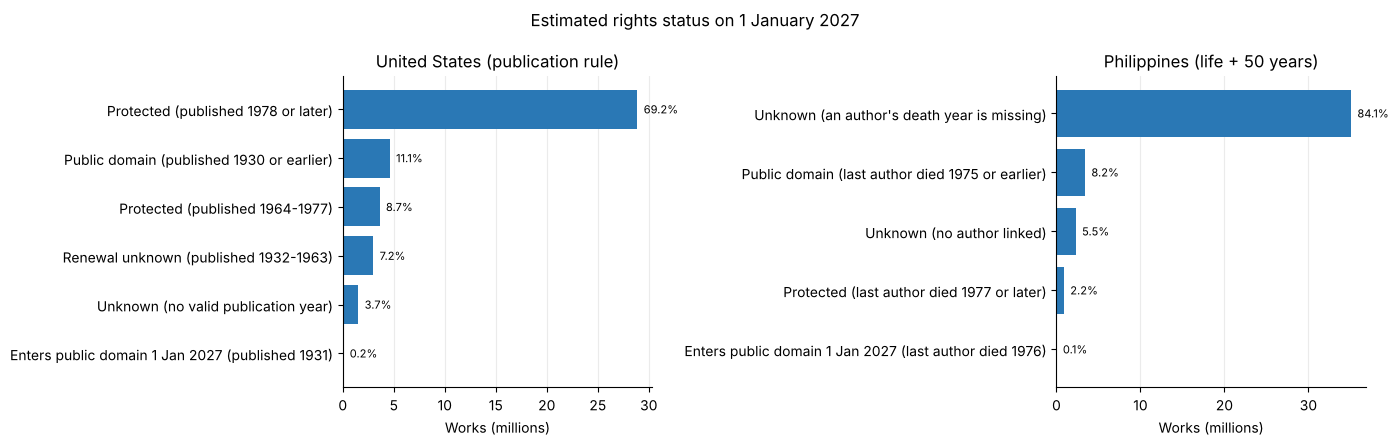

Works by US status (rows) and Philippine status (columns)


PH status,US status,Enters public domain 1 Jan 2027 (last author died 1976),Protected (last author died 1977 or later),Public domain (last author died 1975 or earlier),Unknown (an author's death year is missing),Unknown (no author linked)
,Enters public domain 1 Jan 2027 (published 1931),136,1591,17567,51007,1509
,Protected (published 1964-1977),6485,200137,214077,3069682,128248
,Protected (published 1978 or later),7017,504279,765879,26603641,1008788
,Public domain (published 1930 or earlier),1629,15215,1903568,2448885,241455
,Renewal unknown (published 1932-1963),9415,163495,444313,2313798,75701
,Unknown (no valid publication year),447,18686,71351,597336,846623


In [10]:
fig = helper.plot_status_bars(status_summary["us"], status_summary["ph"])
plt.show()
show(status_summary["crosstab"].reset_index(),
     "Works by US status (rows) and Philippine status (columns)", rows=10,
     floats=0)

The histogram of first-publication years (log scale) shows the steady
growth of publishing, with colours marking the US groups. Two spikes are
**data artefacts** rather than history: 131,598 works are dated exactly
**1900** (about twice the neighbouring years) and 26,149 exactly **1800**,
which look like placeholder dates used by some catalogue sources. Both
are before 1931, so the affected works count as public domain in the US;
if their real dates are later, this group is overstated.

Three data-quality flags quantify the remaining uncertainty:

* **72,390 works** have a first year earlier than their author's birth
  plus 10 years (`year_before_birth`), and **4,697** have authors with
  impossible life dates. These 0.2% are flagged and excluded from every
  list.
* **950,690 works** were first catalogued more than 70 years after their
  last author died (`gap_after_death`). Most are classics whose early
  editions are simply missing (*The Art of War*, *Meditations*). Some,
  however, are modern books linked to the wrong, much older author.
  Section 5.5 measures how often this affects the lists.

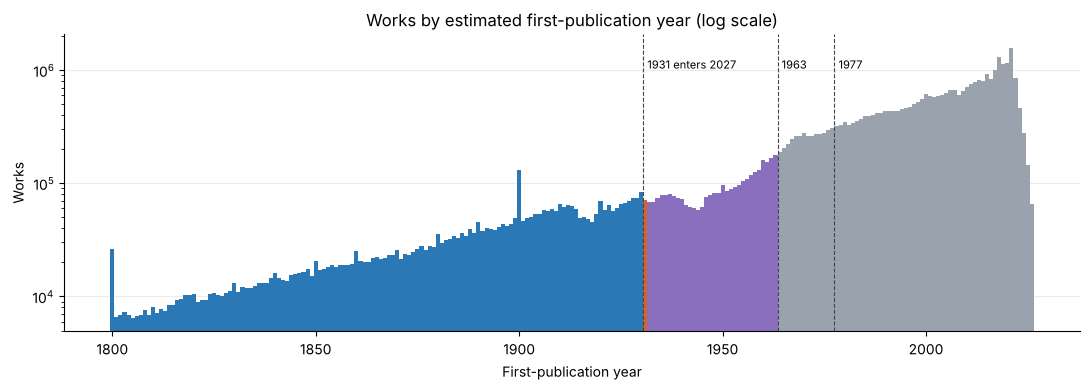

In [11]:
hist = helper.first_year_histogram(status)
fig = helper.plot_first_year_histogram(hist)
plt.show()

### 5.2 Reading activity and Want-to-Read trends

Older works are shelved less often per work than new ones. 3.5% of
public-domain works have at least one Want-to-Read entry, compared with
8.1% of post-1978 works. But because the public-domain group is large,
it still collects **586,358 Want-to-Read entries**, and the 1932-1963 group
another 688,552. Ratings are almost identical across groups (mean 3.9-4.1
stars). A reader who finds an older book is about as satisfied as one
reading a recent title, so age itself does not signal weak demand.

Demand by US rights group


US status,Works,With any WTR (%),Mean WTR per work,Total WTR,WTR Nov 2024-Oct 2025,WTR Nov 2025-Oct 2026,Change (%),Ratings,Mean stars
Public domain (published 1930 or earlier),4610752,3.45,0.13,586358,99449,93757,-5.70,39552,4.07
Enters public domain 1 Jan 2027 (published 1931),71810,3.95,0.11,8176,1324,1137,-14.10,409,3.89
Renewal unknown (published 1932-1963),3006722,4.90,0.23,688552,116918,97820,-16.30,50327,4.04
Protected (published 1964-1977),3618629,5.89,0.21,748284,118546,99222,-16.30,91379,4.00
Protected (published 1978 or later),28889604,8.11,0.30,8621461,1594682,1089496,-31.70,870442,4.00
Unknown (no valid publication year),1534443,3.15,0.06,95928,18794,9823,-47.70,5236,3.92


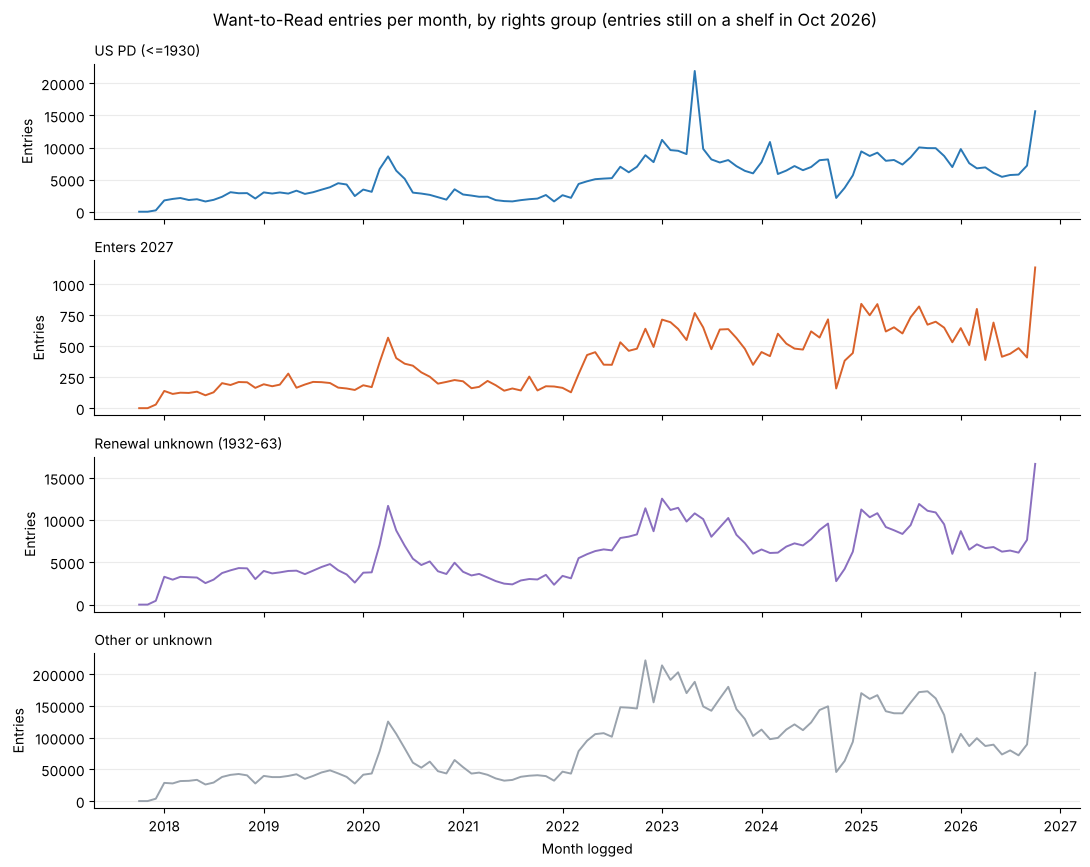

In [12]:
groups = helper.compare_groups(profile)
show(groups[["US status", "works", "pct_with_wtr", "mean_wtr",
             "total_wtr", "wtr_prev_12m", "wtr_last_12m", "wtr_growth_pct",
             "ratings", "mean_rating"]].rename(columns={
    "works": "Works", "pct_with_wtr": "With any WTR (%)",
    "mean_wtr": "Mean WTR per work", "total_wtr": "Total WTR",
    "wtr_prev_12m": "WTR Nov 2024-Oct 2025",
    "wtr_last_12m": "WTR Nov 2025-Oct 2026",
    "wtr_growth_pct": "Change (%)", "ratings": "Ratings",
    "mean_rating": "Mean stars"}),
    "Demand by US rights group", floats=2)
monthly = helper.monthly_want_to_read(tables["reading_log"], status)
fig = helper.plot_monthly_wtr(monthly)
plt.show()

The monthly chart shows four features that matter for interpreting
trends:

1. **Activity grows from 2022.** Monthly entries rise severalfold in
   every group between 2021 and 2023, in step with Open Library's overall
   growth, so raw growth mostly reflects more users rather than more
   interest in particular books.
2. **A sharp dip in October 2024** appears in all four groups at once.
   It coincides with the period when the Internet Archive, which runs Open
   Library, was offline after a cyber-attack, so it reflects service
   availability, not reader interest.
3. **The last month is the highest.** Entries made recently have had the
   least time to be removed from shelves, so recent months are inflated
   relative to older ones (the survivorship effect described in 4.5).
4. **Group spikes.** The public-domain line has an isolated spike in
   May 2023 that does not appear elsewhere. A single popular list or
   import is the likeliest cause, so we do not read it as a trend.

Comparing the last 12 months with the 12 before, entries fell in every
group, but by very different amounts: **−5.7% for US public-domain
works against −31.7% for post-1978 works**. As a result, public-domain works
rose from 5.1% to 6.7% of all Want-to-Read activity. Both windows are
equally affected by the outage dip (it falls in the earlier window) and
by survivorship (which favours the later window), so the *relative*
change between groups is more trustworthy than the absolute decline.

### 5.3 Supply: editions, publishers, scans and Filipino editions

The supply indicators show the expected pattern, plus one notable gap:

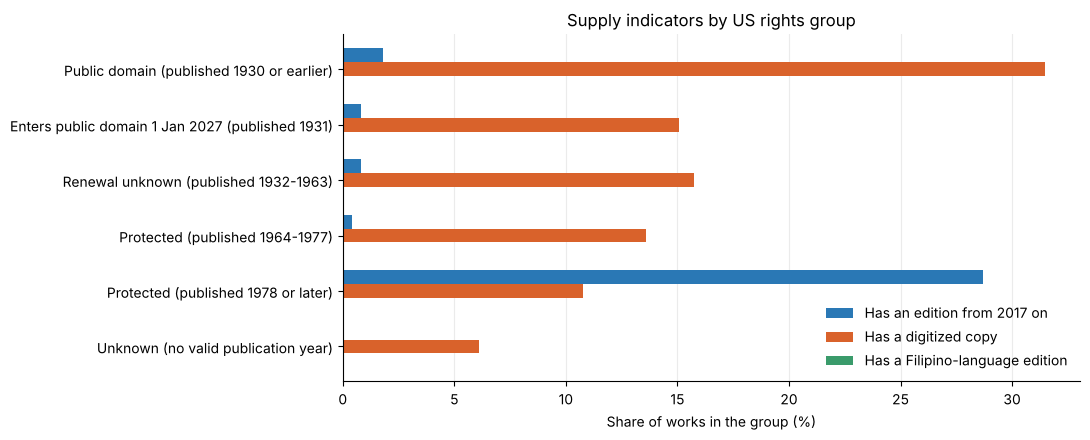

Supply by US rights group


US status,Mean editions,Edition since 2017 (%),Digitized (%),Filipino edition (%)
Public domain (published 1930 or earlier),1.55,1.80,31.47,0.01
Enters public domain 1 Jan 2027 (published 1931),1.35,0.83,15.07,0.00
Renewal unknown (published 1932-1963),1.38,0.80,15.73,0.01
Protected (published 1964-1977),1.28,0.42,13.58,0.01
Protected (published 1978 or later),1.30,28.71,10.78,0.01
Unknown (no valid publication year),0.93,0.00,6.12,0.00


Public-domain and 2027 works: Want-to-Read band x recent editions


Recent editions,Want to Read,0,1-2,3-9,10+
,0,5587423,246848,37874,2932
,1-9,231379,11862,6260,2616
,10-99,5694,812,617,1079
,100-999,200,68,105,352
,1000+,3,1,3,62


In [13]:
fig = helper.plot_supply_comparison(groups)
plt.show()
show(groups[["US status", "mean_editions", "pct_with_recent_edition",
             "pct_digitized", "pct_filipino"]].rename(columns={
    "mean_editions": "Mean editions",
    "pct_with_recent_edition": "Edition since 2017 (%)",
    "pct_digitized": "Digitized (%)",
    "pct_filipino": "Filipino edition (%)"}),
    "Supply by US rights group", floats=2)
grid = helper.demand_supply_grid(profile)
show(grid.reset_index(),
     "Public-domain and 2027 works: Want-to-Read band x recent editions",
     floats=0)

* **Recent editions are rare for older works.** Only 1.8% of US
  public-domain works, 0.8% of 1931 works and 0.8% of 1932-1963 works have
  an edition dated 2017 or later, compared with 28.7% of post-1978 works.
  Most old works are effectively out of print in the catalogue.
* **Scans are common for older works.** 31.5% of public-domain works have
  an Internet Archive scan, roughly three times the rate for post-1978
  works. A scan does not mean the book is free to read online, though:
  in-copyright scans are only lent, one reader at a time.
* **Filipino-language editions are almost absent.** Across the whole
  catalogue only 4,252 works (4,619 editions) are catalogued in Tagalog
  or Filipino, about 0.01% in every group. Part of this is under-cataloguing
  of Philippine publishers in Open Library, but the gap is large enough to
  suggest a real shortage of Filipino editions of world literature.

The demand-supply grid restricts attention to works that are potentially
public domain or enter in 2027. Of the 794 such works with 100 or more
Want-to-Read entries, **203 have no edition since 2017** (3 of them with
over 1,000 entries). These are the clearest "wanted but not reissued"
cases. The grid also shows that the most-wanted public-domain works
usually do have many recent editions (62 of the 69 works with 1,000+
entries have ten or more), so the opportunity lies in the less famous
middle of the demand distribution.

### 5.4 The 2027 watchlist

96,544 unflagged works enter the public domain on 1 January 2027. Only 6.0%
of them have any Want-to-Read entry, and 98% have no edition since 2017, so
demand is the selective criterion. The **53-work watchlist** splits into
36 works that enter through the **Philippine rule** (last author died 1976)
and 17 through the **US rule** (published 1931). Of the 53, 42 have no
edition since 2017 and none has a Filipino edition. 52 have an Internet
Archive scan, so a digitized source text is usually available to work
from.

Works entering the public domain on 1 January 2027


route,flagged,works,with_wtr,total_wtr,no_recent_edition,with_filipino_edition
US only (published 1931),False,71520,2816,7865,70932,3
PH only (author died 1976),False,24888,2994,33945,24032,6
US and PH,False,136,11,180,132,0
US only (published 1931),True,154,10,131,149,0
PH only (author died 1976),True,105,9,224,101,0


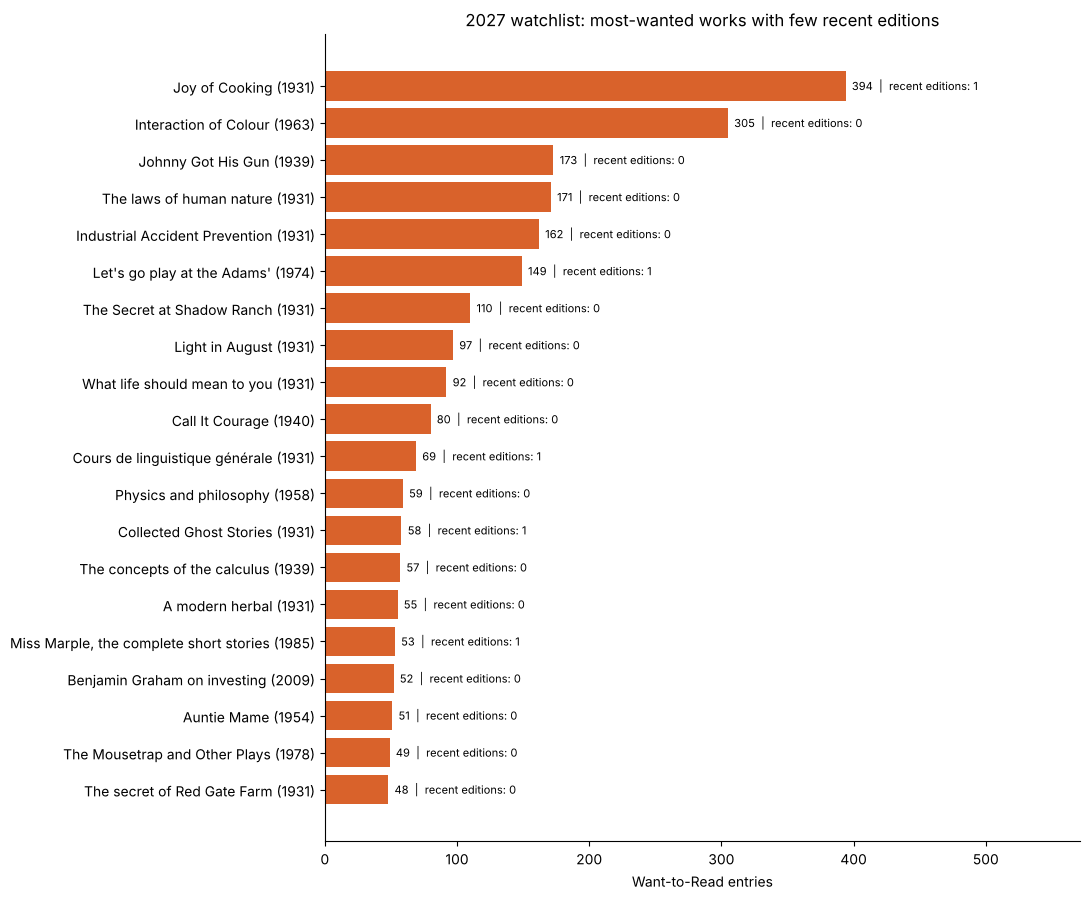

Top 25 of the 2027 watchlist


title,authors,first_year,last_death_year,want_to_read,wtr_last_12m,ratings_count,ratings_mean,n_editions,n_recent_editions,n_digitized,n_filipino_editions,gap_after_death
Joy of Cooking,"Irma S. Rombauer, Marion Rombauer Becker, Ethan Becker, John Becker, Megan Scott",1931,1962,394,31,14,4.79,67,1,16,0,False
Interaction of Colour,Joseph Albers,1963,1976,305,15,7,4.43,21,0,3,0,False
Johnny Got His Gun,Dalton Trumbo,1939,1976,173,24,16,3.81,42,0,8,0,False
The laws of human nature,"Wheeler, Raymond Holder",1931,1962,171,82,4,4.25,2,0,2,0,False
Industrial Accident Prevention,Herbert William Heinrich,1931,<NA>,162,9,12,3.67,5,0,1,0,False
Let's go play at the Adams',Mendal W. Johnson,1974,1976,149,5,4,4.00,7,1,2,0,False
The Secret at Shadow Ranch,Leslie McFarlane,1931,1977,110,36,9,4.22,41,0,22,0,False
Light in August,William Faulkner,1931,1962,97,11,10,3.10,73,0,17,0,False
What life should mean to you,Alfred Adler,1931,1937,92,12,2,5.00,13,0,3,0,False
Call It Courage,Armstrong Sperry,1940,1976,80,4,4,4.00,51,0,16,0,False


Authors with the most Want-to-Read entries among 2027 entrants


name,works,want_to_read,works_without_recent_edition,via_us_1931,via_ph_1976
Agatha Christie,1012,22008,804,2,1012
Benjamin Graham,28,4389,22,0,28
Martin Heidegger,722,605,701,0,722
Paul Gallico,84,410,78,0,84
Marion Rombauer Becker,1,394,0,1,0
Irma S. Rombauer,1,394,0,1,0
Megan Scott,1,394,0,1,0
Ethan Becker,1,394,0,1,0
John Becker,1,394,0,1,0
Virginia Woolf,3,332,2,3,0


In [14]:
breakdown = helper.entering_2027_breakdown(profile)
show(breakdown, "Works entering the public domain on 1 January 2027")
fig = helper.plot_watchlist(watchlist, top_n=20)
plt.show()
show(watchlist[["title", "authors", "first_year", "last_death_year",
                "want_to_read", "wtr_last_12m", "ratings_count",
                "ratings_mean", "n_editions", "n_recent_editions",
                "n_digitized", "n_filipino_editions", "gap_after_death"]],
     "Top 25 of the 2027 watchlist", rows=25)
entering_authors = helper.top_authors(profile, tables["authors"],
                                      "enters_2027", top_n=15)
show(entering_authors.drop(columns="author_key"),
     "Authors with the most Want-to-Read entries among 2027 entrants",
     rows=15)

**Reading the watchlist.** Each row is a lead, and checking the top
entries against standard bibliographies shows why it must be verified:

* ***Joy of Cooking*** (Irma S. Rombauer, 1931) is the most-wanted
  entrant. Only the **original 1931 text** enters the US public domain;
  the many later revisions by her co-authors remain protected.
* ***Interaction of Colour***, ***Johnny Got His Gun***, ***Call It
  Courage***, Heisenberg's ***Physics and Philosophy*** and
  ***Auntie Mame*** enter through the Philippine rule. Their authors
  (Albers, Trumbo, Sperry, Heisenberg, Patrick Dennis) all died in 1976.
  In the US these works are either protected or depend on an unchecked
  renewal.
* ***Light in August*** is a **false positive**. Open Library's earliest
  edition is dated 1931, but the novel was published in 1932, so it
  enters the US public domain in 2028. ***Cours de linguistique
  générale*** (1916) is the reverse case: it is listed as 1931 but is
  already free.
* ***The laws of human nature*** (R. H. Wheeler, 1931) gained 82 of its
  171 entries in the last year. That pattern suggests readers confusing it
  with Robert Greene's 2018 bestseller of almost the same title, so its
  demand is probably overstated.
* ***Savage Surrender*** (credited to Pamela Clare, died 1976 according
  to the catalogue) appears to merge two different authors and needs
  checking before any decision.

The table of authors shows how concentrated the 2027 opportunity is.
**Agatha Christie alone accounts for 1,012 entering works and 22,008
Want-to-Read entries**, more than every other entrant combined. In the
Philippines all of her works become free on 1 January 2027. Elsewhere
most stay protected much longer: until 2047 under life + 70, and in the
US for 95 years from publication (only her books published in 1931 or
earlier are free there). Other 1976 deaths with
sizeable catalogues are Benjamin Graham (28 works), Martin Heidegger
(722), Paul Gallico (84), Josef Albers (81), Lin Yutang (441) and
Samuel Eliot Morison (393). Almost all of their works lack recent
editions in the catalogue, and none of Christie's has a Filipino
edition.

**Sensitivity.** The cut-offs change the size of the list but not its
top. Relaxing the demand threshold to the 95th percentile (9 entries)
gives 283 works, and to the 90th percentile (5 entries) gives 625.
Allowing up to five recent editions adds only 27 works at the 99th
percentile (53 to 80). The low-supply condition is not the binding
constraint, because almost no 2027 entrant has been reissued recently.

In [15]:
sensitivity = helper.watchlist_sensitivity(profile).reset_index()
sensitivity["WTR quantile"] = sensitivity["WTR quantile"].map("{:.0%}".format)
show(sensitivity,
     "Watchlist size under other cut-offs (columns: max recent editions)",
     floats=0)

Watchlist size under other cut-offs (columns: max recent editions)


max recent editions,WTR quantile,WTR threshold,0,1,2,5
,90%,5,583,625,643,690
,95%,9,255,283,294,332
,99%,33,42,53,56,80


### 5.5 Works that are potentially public domain already

The second deliverable lists works that are **potentially public domain
already**, with the same demand threshold (at least 33 Want-to-Read
entries); 2,352 works qualify. The most wanted of them are dominated by
works that are free **only under the Philippine rule** (US status
"renewal": published 1932-1963): *Think and Grow Rich* (Napoleon Hill,
died 1970, 16,158 entries), *How to Win Friends and Influence People*
(Dale Carnegie, died 1955), *The Hobbit* and *The Lord of the Rings*
(Tolkien, died 1973), *Animal Farm* (Orwell, died 1950), *Le Petit
Prince* (Saint-Exupéry, died 1944) and *No Longer Human* (Dazai, died
1948). Most of these already have dozens of recent editions, so they are
crowded markets. The second table applies the low-supply filter as well.

In [16]:
show(pd_list[["title", "authors", "first_year", "last_death_year",
              "us_code", "ph_code", "want_to_read", "n_recent_editions",
              "n_recent_publishers", "n_digitized",
              "n_filipino_editions", "gap_after_death"]],
     "Most-wanted works estimated to be public domain", rows=25)
pd_low_supply = helper.build_pd_list(
    profile, min_want_to_read=min_wtr, top_n=50, authors=tables["authors"],
    max_recent_editions=MAX_RECENT_EDITIONS)
show(pd_low_supply[["title", "authors", "first_year", "last_death_year",
                    "us_code", "ph_code", "want_to_read", "wtr_last_12m",
                    "n_editions", "n_recent_editions", "n_digitized",
                    "gap_after_death"]],
     "High demand, at most one edition since 2017", rows=20)
show(helper.list_flag_summary(profile, min_wtr),
     "Listed works whose author link needs checking (gap_after_death)")
ph_authors = helper.philippine_authors_summary(profile)
show(ph_authors[["PH status", "works", "total_wtr",
                 "with_filipino_edition"]],
     "Works by authors with Philippine citizenship (Wikidata)")

Most-wanted works estimated to be public domain


title,authors,first_year,last_death_year,us_code,ph_code,want_to_read,n_recent_editions,n_recent_publishers,n_digitized,n_filipino_editions,gap_after_death
Think and Grow Rich,Napoleon Hill,1937,1970,renewal,pd,16158,93,57,55,0,False
How to Win Friends and Influence People,Dale Carnegie,1936,1955,renewal,pd,13484,40,26,49,0,False
Pride and Prejudice,Jane Austen,1813,1817,pd,pd,6756,2290,176,289,0,False
The Art of War,孙武 (Sun Tzu),1900,-470,pd,pd,5473,807,118,54,0,True
人間失格,太宰 治,1948,1948,renewal,pd,4106,18,11,1,0,False
The Hobbit,J.R.R. Tolkien,1937,1973,renewal,pd,4068,52,22,86,0,False
Le petit prince,Antoine de Saint-Exupéry,1943,1944,renewal,pd,4028,235,94,39,1,False
Animal Farm,George Orwell,1945,1950,renewal,pd,4014,365,70,41,0,False
Metamorphosis,Franz Kafka,1915,1924,pd,pd,3648,535,78,26,0,False
The Richest Man in Babylon,George S. Clason,1926,1957,pd,pd,3410,128,58,21,0,False


High demand, at most one edition since 2017


title,authors,first_year,last_death_year,us_code,ph_code,want_to_read,wtr_last_12m,n_editions,n_recent_editions,n_digitized,gap_after_death
Games People Play,Eric Berne,1964,1970,protected_pre78,pd,1881,284,57,0,8,False
Madilog,Tan Malaka,1951,1949,renewal,pd,1084,217,4,0,0,False
Las 48 leyes del poder,Robert Greene,1998,1592,protected_post78,pd,1021,82,3,0,0,True
Alice in Wonderland in Five Acts,Lewis Carroll,1897,1898,pd,pd,873,8,1,0,1,False
Outwitting the devil,Napoleon Hill,2011,1970,protected_post78,pd,825,149,5,0,1,False
Picasso,"Pablo Picasso, Jean-Louis Andral, Pierre Daix",1926,1973,pd,unknown_death,812,58,240,0,5,False
The Chronicles of Narnia,C. S. Lewis,1970,1963,protected_pre78,pd,764,120,60,1,4,False
The Wealth of Nations,Adam Smith,1776,1790,pd,pd,697,66,124,0,38,False
La Poetica,Aristotle,1479,-322,pd,pd,692,106,498,0,79,True
Anatomy,"Henry Gray F.R.S., Henry Vandyke Carter",1858,1897,pd,pd,683,61,109,0,41,False


Listed works whose author link needs checking (gap_after_death)


list,works,gap_after_death,gap_pct
"potentially public domain, high demand",2352,268,11.40
... and at most one recent edition,1245,179,14.40
"enters 2027, high demand",146,1,0.70


Works by authors with Philippine citizenship (Wikidata)


PH status,works,total_wtr,with_filipino_edition
Public domain (last author died 1975 or earlier),513,1418,64
Unknown (an author's death year is missing),345,2427,32
Protected (last author died 1977 or later),328,1393,25
Enters public domain 1 Jan 2027 (last author died 1976),4,0,1


The **low-supply view** (1,245 works) surfaces less obvious leads: Eric
Berne's *Games People Play* (1,881 entries, no edition since 2017; free
in the Philippines since Berne died in 1970), Tan Malaka's *Madilog*
(1,084 entries) and several C. S. Lewis titles (died 1963). It also
shows the two main failure modes of the estimates:

* **Wrong author link.** *Las 48 leyes del poder* (Robert Greene, 1998)
  appears because its author record carries the death year of the
  Elizabethan writer Robert Greene (1592). It is a false positive, and it
  is marked by `gap_after_death`. This warning fires on 11.4% of the
  high-demand public-domain list and 14.4% of its low-supply subset, but on
  only 1 of the 146 high-demand 2027 entrants. Every flagged row needs
  its author checked before use.
* **Duplicate work records.** Classics such as *The Wealth of Nations* or
  *Paradise Lost* show hundreds of editions but none since 2017. Open
  Library often splits one title across several work records, and recent
  editions attached to a duplicate are not counted, so "low supply"
  is least reliable for very famous titles.

Finally, only **78 authors** in the Wikidata dump are marked as Philippine
citizens. Their 1,190 catalogued works include 513 already free in the
Philippines, but they carry few reading-log entries. Philippine authors
are under-represented in both Wikidata links and Open Library activity,
so this analysis cannot yet measure local demand for local classics.

### 5.6 Limitations

* **Missing and wrong death years.** Only 3.7% of authors have a death
  year, so 84% of works are "unknown" under the life-based rule. Where Open
  Library and Wikidata both give a year they agree for 98.8% of authors
  (within one year), and only 75 authors would change Philippine status
  depending on the source. Errors therefore come mainly from *wrong
  links* between works and authors, which no single-source check can
  detect.
* **Publication years.** First years come from the earliest catalogued
  edition. They can be too early (a misdated edition, as with *Light in
  August*), too late (old editions missing, 950,690 works), or
  placeholders (the 1900 and 1800 spikes).
* **US renewals.** The 3.0 million works first published 1932-1963 cannot
  be classified without US Copyright Office renewal records, which are
  not in the dumps. We also ignore special US cases: works by US
  government authors (always public domain), works published without a
  copyright notice before 1978, and foreign works whose US copyright was
  restored in 1996.
* **Philippine law.** We apply only the general life + 50 rule (RA 8293
  sec. 213-214). We do not model works of corporate or anonymous authorship,
  works published after the author's death, or the separate rights of
  translators and editors. A new translation must start from a source
  text that is itself free.
* **Work-level counts.** A "work" bundles all its editions and
  translations. Revised editions (*Joy of Cooking*) and compilations
  (Christie omnibus volumes) add new material that may still be protected.
  Duplicate work records split editions and understate supply.
* **Demand.** Reading-log and rating activity reflects Open Library users
  only, who are not representative of all readers (and certainly not of
  Philippine readers). The dump keeps only entries still on a shelf,
  undercounting older months, and the October 2024 outage depresses one
  month.
* **Scope.** The analysis is descriptive. The thresholds (99th percentile
  of demand, at most one recent edition) are judgement calls whose effect
  we report in Section 5.4, and no estimate here is legal advice.

### 5.7 Recommendations

1. **Act on the Philippine 2027 opportunity first.** The clearest lead is
   the Agatha Christie catalogue, which enters the public domain in the
   Philippines on 1 January 2027 with substantial demand and no Filipino
   editions. Working from the original English texts (not later
   translations or revised compilations), a Philippine publisher could
   prepare Tagalog or Filipino translations of the most-wanted titles,
   after legal confirmation of the date of death and of the local term.
2. **Verify each watchlist row before acting.** Check the first edition
   against a national bibliography (this catches cases such as *Light in
   August*), confirm the author's identity and death date, and inspect
   any row marked `gap_after_death`. The 53-work list is short enough to
   check by hand in a few days.
3. **Resolve the 1932-1963 renewal question.** Matching these 3.0 million
   works against digitized US renewal records, for example Stanford's
   Copyright Renewal Database of books from 1923-1963, would turn the
   largest "uncertain" group into firm answers. That is the most valuable
   extension of this pipeline.
4. **Improve author dates at the source.** Because the Philippine estimate
   is limited mainly by missing death years and mislinked authors,
   adding Wikidata links to the most-shelved Open Library authors (and
   fixing the conflations found here) would raise coverage for everyone
   using the data.
5. **Re-run monthly.** The pipeline reuses its Parquet tables, so each new
   dump can refresh the lists in about an hour. In late 2027 the same
   code, with `REFERENCE_DATE` set to 2028, produces the next year's
   watchlist (works from 1932 and deaths in 1977).

## References

- Open Library. *Data dumps* (monthly bulk exports of works, editions,
  authors, Wikidata links, reading logs and ratings), dump of 31 October
  2026. <https://openlibrary.org/developers/dumps>; mirrored at
  <https://archive.org/details/ol_dump_2026-10-31>.
- Wikidata. Properties P569 (date of birth), P570 (date of death), P648
  (Open Library ID) and P27 (country of citizenship).
  <https://www.wikidata.org>
- *Copyright Act of 1976*, 17 U.S.C. sections 302-305 (duration of
  copyright), as amended by the Copyright Term Extension Act of 1998.
- U.S. Copyright Office (2019). *Circular 15A: Duration of Copyright*;
  and Cornell University Library, *Copyright Term and the Public Domain
  in the United States* (updated each January).
- Republic Act No. 8293, *Intellectual Property Code of the Philippines*
  (1997), sections 213 (term of protection) and 214 (calculation of
  term).
- Apache Software Foundation. *PySpark 4.0 documentation*: `from_json`,
  higher-order array functions, and the Parquet data source.
  <https://spark.apache.org/docs/latest/api/python/>

In [17]:
spark.stop()